# Vit timm XAI

## Load dataset

In [1]:
from pathlib import Path
from collections import Counter
from monai.data import Dataset

import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

from monai.transforms import (
    Compose,
    LoadImaged,
    EnsureChannelFirstd,
    Resized,
    ScaleIntensityd,
    EnsureTyped,
)

DATA_DIR = Path(r"..\..\data\brain-tumor-mri-classification\merged_dataset_v3\images")
assert DATA_DIR.exists(), f"Not found: {DATA_DIR.resolve()}"   # relative path depends on the notebook's working directory

class_names = ["glioma", "meningioma", "no_tumor", "pituitary"]
class_to_idx = {name: idx for idx, name in enumerate(class_names)}

def get_image_files(split):
    data = []
    for class_name in class_names:
        class_dir = DATA_DIR / split / class_name
        for image_path in sorted(class_dir.iterdir()):          # sorted = deterministic order
            if image_path.suffix.lower() in [".jpg", ".jpeg", ".png"]:
                data.append({"image": str(image_path), "label": class_to_idx[class_name]})
    return data

transforms = Compose([
    LoadImaged(keys=["image"]),
    EnsureChannelFirstd(keys=["image"]),
    Resized(keys=["image"], spatial_size=(224, 224)),
    ScaleIntensityd(keys=["image"]),
    EnsureTyped(keys=["image"]),
])

test_files = get_image_files("test")

test_dataset = Dataset(data=test_files, transform=transforms)

print("test:", len(test_files))
print("test per class:", Counter(class_names[d["label"]] for d in test_files))
print("sample:", tuple(test_dataset[0]["image"].shape))

C:\Users\user\anaconda3\envs\monai\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


test: 246
test per class: Counter({'glioma': 81, 'pituitary': 61, 'meningioma': 55, 'no_tumor': 49})
sample: (3, 224, 224)


## Load Model

In [2]:
import torch
import timm
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from collections import Counter

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

MODEL_PATH = Path("../../models/vit_base_patch16_224.pt")

model = timm.create_model(
    "vit_base_patch16_224",
    pretrained=False,
    num_classes=4
)

state_dict = torch.load(
    MODEL_PATH,
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(state_dict, strict=True)

model = model.to(device)
model.eval()

print(model)

VisionTransformer(
  (patch_embed): PatchEmbed(
    (proj): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
    (norm): Identity()
  )
  (pos_drop): Dropout(p=0.0, inplace=False)
  (patch_drop): Identity()
  (norm_pre): Identity()
  (blocks): Sequential(
    (0): Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (q_norm): Identity()
        (k_norm): Identity()
        (attn_drop): Dropout(p=0.0, inplace=False)
        (norm): Identity()
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (ls1): Identity()
      (drop_path1): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): Mlp(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (drop1): Dropout(p=0.0, inplace=False

## Apply Attention Rollout

In [3]:
@torch.no_grad()
def attention_rollout(model, x):
    attention_maps = []
    hooks = []

    for block in model.blocks:
        attn = block.attn

        def hook_fn(module, inputs, output, attn=attn):
            B, N, C = output.shape

            qkv = output.reshape(
                B, N, 3, attn.num_heads, attn.head_dim
            ).permute(2, 0, 3, 1, 4)

            q, k, v = qkv.unbind(0)

            q = attn.q_norm(q)
            k = attn.k_norm(k)

            attention = (q * attn.scale) @ k.transpose(-2, -1)
            attention = attention.softmax(dim=-1)
            attention = attention.mean(dim=1)

            attention_maps.append(attention)

        hooks.append(
            attn.qkv.register_forward_hook(hook_fn)
        )

    try:
        model.eval()
        logits = model(x)
    finally:
        for hook in hooks:
            hook.remove()

    num_tokens = attention_maps[0].shape[-1]

    identity = torch.eye(
        num_tokens, device=x.device
    ).unsqueeze(0)

    rollout = identity.clone()

    for attention in attention_maps:
        attention = attention + identity
        attention = attention / attention.sum(dim=-1, keepdim=True)
        rollout = attention @ rollout

    cls_attention = rollout[:, 0, 1:]

    grid_size = int(cls_attention.shape[-1] ** 0.5)

    attention_map = cls_attention.reshape(
        1, 1, grid_size, grid_size
    )

    attention_map = (
        attention_map - attention_map.min()
    ) / (
        attention_map.max() - attention_map.min() + 1e-8
    )

    return attention_map.squeeze(), logits

In [4]:
class_names = ["glioma", "meningioma", "no_tumor", "pituitary"]


def show_rollout(model, sample, device):

    x = sample["image"].unsqueeze(0).to(device)

    attention_map, logits = attention_rollout(model, x)

    true_label = int(sample["label"])
    predicted_label = logits.argmax(dim=1).item()

    # Upsample attention map
    heatmap = F.interpolate(
        attention_map[None, None],
        size=(224, 224),
        mode="bilinear",
        align_corners=False
    )[0, 0].cpu().numpy()

    # Original image
    img = (
        x[0]
        .permute(1, 2, 0)
        .cpu()
        .numpy()
        .clip(0, 1)
    )

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))

    axes[0].imshow(img)
    axes[0].set_title(
        f"Original | True: {class_names[true_label]}"
    )

    axes[1].imshow(heatmap, cmap="jet")
    axes[1].set_title("Attention Rollout")

    axes[2].imshow(img)
    axes[2].imshow(
        heatmap,
        cmap="jet",
        alpha=0.45
    )
    axes[2].set_title(
        f"Overlay | Pred: {class_names[predicted_label]}"
    )

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

glioma | rf_test_glioma_725.jpg


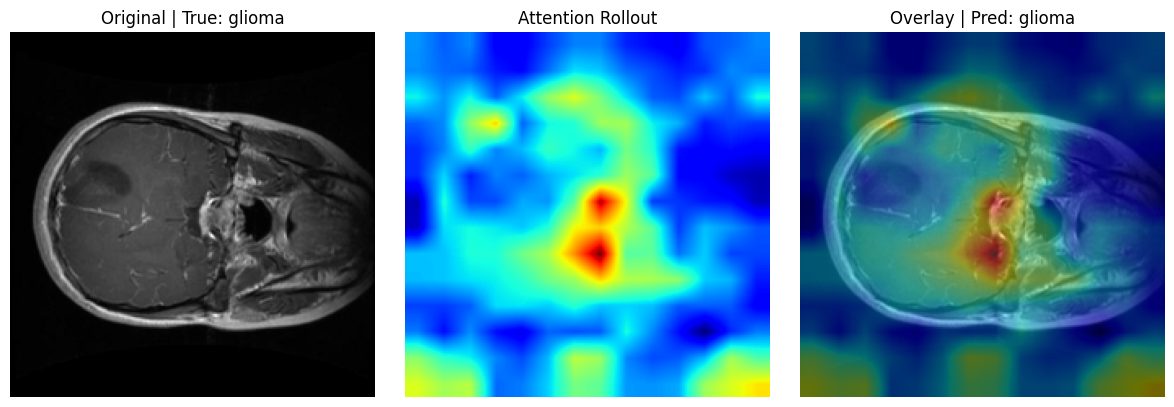

meningioma | rf_test_meningioma_491.jpg


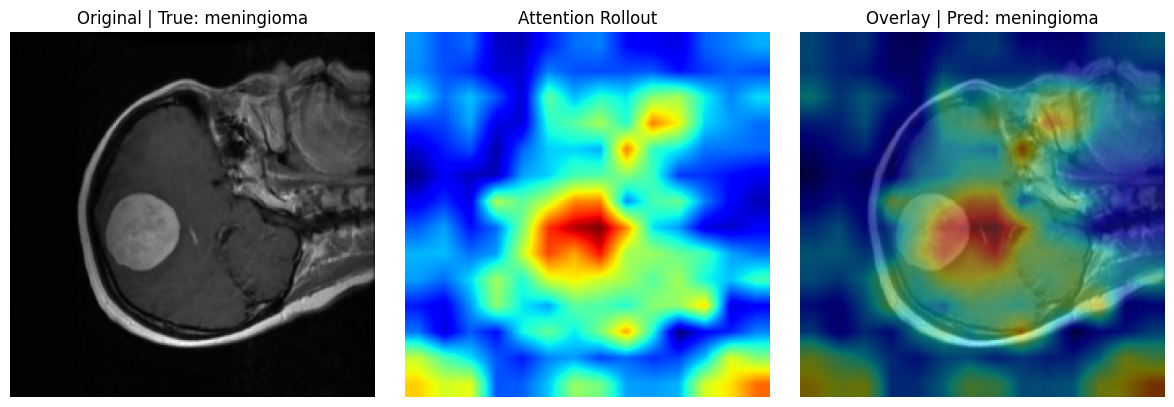

no_tumor | rf_test_no_tumor_435.jpg


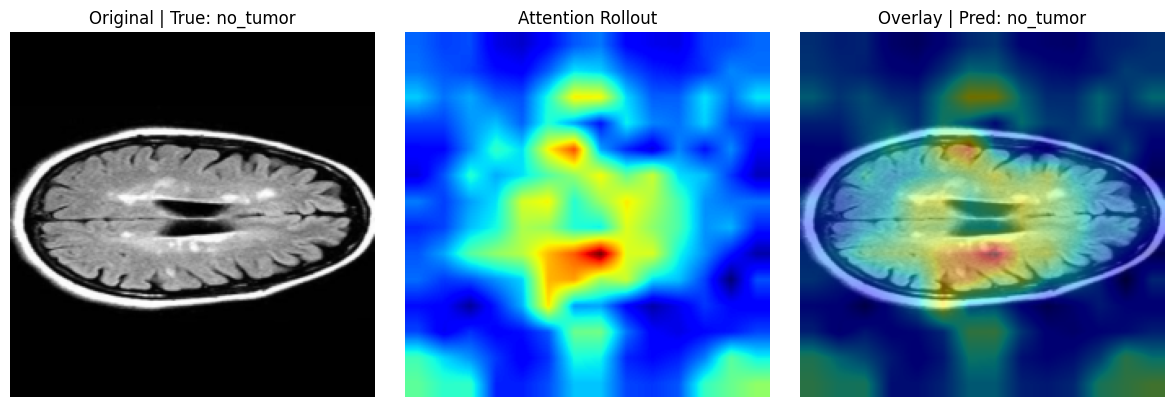

pituitary | rf_test_pituitary_550.jpg


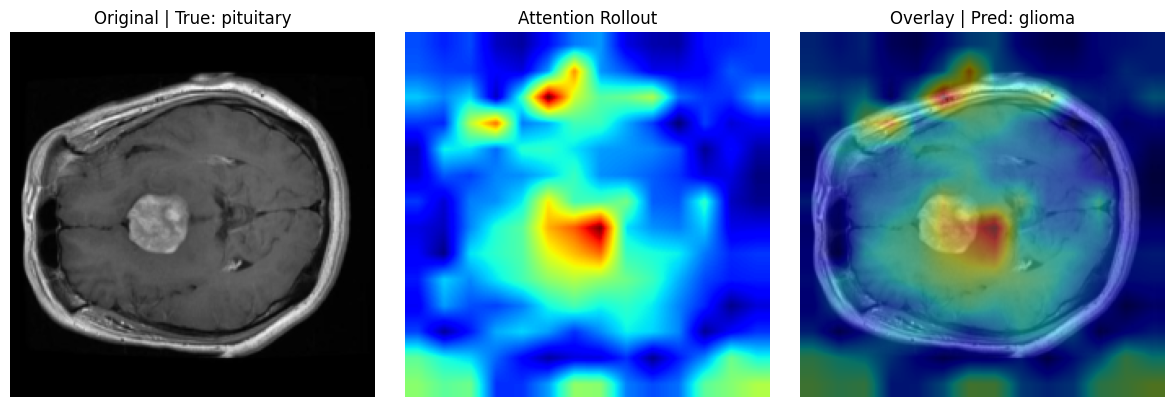

In [5]:
by_class = {}

for idx, data in sorted(
    enumerate(test_files),
    key=lambda item: item[1]["image"]
):
    by_class.setdefault(data["label"], idx)


for class_idx in sorted(by_class):

    image_idx = by_class[class_idx]

    print(
        f"{class_names[class_idx]} | "
        f"{Path(test_files[image_idx]['image']).name}"
    )

    show_rollout(
        model,
        test_dataset[image_idx],
        device
    )